# Function-to-function maps and operator problems

What exactly is the input, output and domain of a learned PDE map?

Fall 2024.


# Specify the operator
Predict which quantity stays fixed under sealed heat flow. State whether your desired output is a field at one time, a trajectory or a scalar.

In [1]:
import numpy as np
from operator_bench import field, project, dataset
from demo import run
from IPython.display import SVG, display
coeff=np.array([1.,0.3,-0.15,0.1])
for n in [32,64,128]:
    values=field(coeff,n,T=0.1)
    print(n,"samples; mean",values.mean())

32 samples; mean 1.0
64 samples; mean 1.0
128 samples; mean 1.0


## Implement one attenuation
Complete the exponent from the mode-decay equation. This guided check uses a first-mode rate of1 and time0.2; it is separate from the assigned calculation.

In [2]:
def my_gain(kappa,mode,length,time):
    exponent=None  # TODO: negative mode-decay rate times time
    return None if exponent is None else np.exp(exponent)
trial=my_gain(1/np.pi**2,1,1,0.2)
if trial is None:
    print("Complete the exponent, then rerun.")
else:
    np.testing.assert_allclose(trial,np.exp(-0.2),rtol=0,atol=1e-14)
    print("Guided gain check passed:",trial)

Complete the exponent, then rerun.


Whole-case overlap: set()


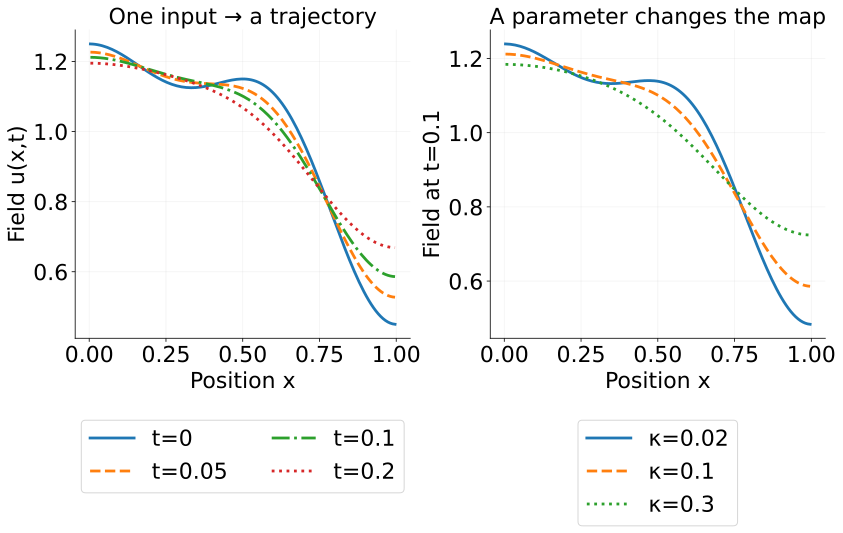

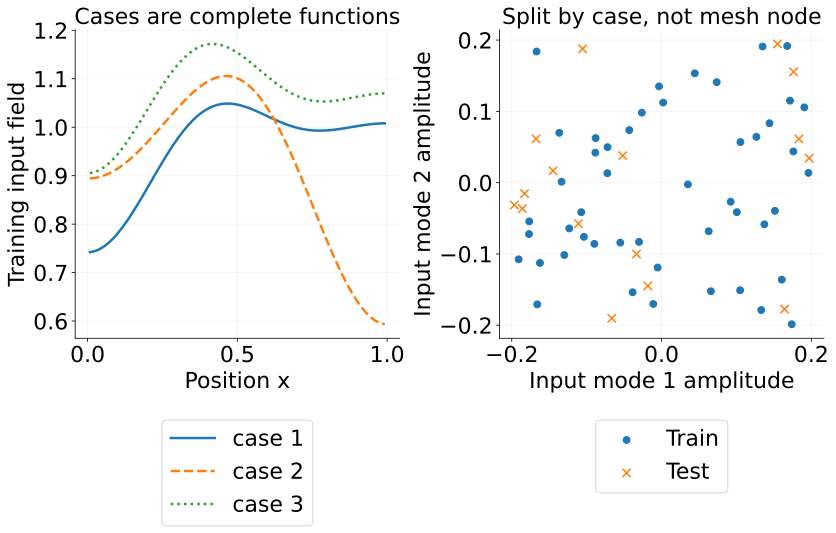

In [3]:
train=dataset(seed=1701)
test=dataset(count=16,seed=1702)
print("Whole-case overlap:",set(train["ids"]) & set(test["ids"]))
results=run()
display(SVG(filename="operator-family.svg"))
display(SVG(filename="dataset-regimes.svg"))

## Modify and interpret
Change only diffusivity to0.02 at the same final time. Predict whether spatial variation decays more or less. Then write a dataset card with input modes, parameter, horizon, grid and complete-case split.

In [4]:
for kappa in [0.1,0.02]:
    output=field(coeff,128,kappa=kappa,T=0.1)
    print("kappa",kappa,"mean",output.mean(),"spatial standard deviation",output.std())

kappa 0.1 mean 1.0 spatial standard deviation 0.207106671323724
kappa 0.02 mean 1.0 spatial standard deviation 0.23742265332621995


Record one verified numerical property and one regime this dataset does not cover. Optional: add a fourth mode with an adequately resolved grid and derive its expected attenuation.